# A Keras-like neural network from scratch

*Coded along with Eric Ma's deep learning workshop at SciPy 2019 ([`ericmjl/dl-workshop`](https://github.com/ericmjl/dl-workshop)).*

**Goal:** classify molecules as biodegradable or not (41 features per molecule, binary label) using a two-layer neural network written with NumPy and automatic differentiation, without a deep learning framework.

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

In [1]:
try:
    from jax import grad
except ImportError:
    from autograd import grad
import pandas as pd
from tqdm.autonotebook  import tqdm
import autograd.numpy as np

X = pd.read_csv("C:/PyLuigi/Py Courses/dl-workshop-master/data/biodeg_X.csv", index_col=0)
y = pd.read_csv("C:/PyLuigi/Py Courses/dl-workshop-master/data/biodeg_y.csv", index_col=0)

X

C:\Users\Louis\AppData\Local\Temp\ipykernel_28252\1065577068.py:6: TqdmExperimentalWarning: Using `tqdm.autonotebook.tqdm` in notebook mode. Use `tqdm.tqdm` instead to force console mode (e.g. in jupyter console)
  from tqdm.autonotebook  import tqdm


,spmax_l,j_dz_e_,nhm,f01[n_n],f04[c_n],nssssc,ncb_,c%,ncp,no,...,ncrt,c_026,f02[c_n],nhdon,spmax_b_m_,psi_i_a,nn,sm6_b_m_,narcoor,nx
0,-1.579116,-0.455436,-0.489991,-0.166611,-0.420109,-0.270120,-0.740035,-0.618477,0.317642,-1.015972,...,-0.201625,-0.581014,-0.560635,-0.764620,-0.969625,-1.505087,-0.629368,-1.108299,-0.160469,-0.322970
1,-1.120179,-1.148921,-0.489991,-0.166611,-0.420109,-0.270120,-0.740035,-0.684090,-0.191647,-0.452729,...,-0.201625,-0.581014,-0.560635,-0.764620,-0.603480,-0.920114,-0.629368,-1.105078,-0.160469,-0.322970
2,-1.555346,0.218562,-0.489991,-0.166611,-0.420109,-0.270120,-0.740035,-1.132449,0.317642,1.236998,...,-0.201625,-0.581014,-0.560635,0.030917,-0.842575,-0.220014,-0.629368,-0.828102,-0.160469,-0.322970
3,-3.259447,-0.432701,-0.489991,-0.166611,-0.420109,-0.270120,-0.740035,-1.865132,-0.700936,0.110513,...,-0.201625,-0.581014,-0.560635,0.030917,-0.872587,3.798563,-0.629368,-1.561605,-0.160469,-0.322970
4,-0.999502,0.390820,-0.489991,-0.166611,-0.420109,-0.270120,-0.740035,-0.837188,0.317642,1.236998,...,-0.201625,-0.581014,-0.560635,-0.764620,-0.567466,-0.238683,-0.629368,-0.504427,-0.160469,-0.322970
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1050,1.185477,-0.209318,-0.489991,-0.166611,-0.420109,1.592474,-0.740035,-0.541928,1.336220,-0.452729,...,2.903689,-0.581014,2.077894,0.030917,-0.345377,-0.492275,0.287736,-0.435989,-0.160469,-0.322970
1051,0.922183,0.365318,-0.489991,-0.166611,3.437660,-0.270120,-0.740035,-0.191989,-0.700936,4.053210,...,-0.201625,-0.581014,0.758629,-0.764620,-0.131292,0.816135,2.121944,0.522154,-0.160469,-0.322970
1052,0.157897,-1.566817,-0.489991,3.739480,3.437660,-0.270120,1.507336,0.803148,-0.700936,1.236998,...,-0.201625,2.049756,5.156179,-0.764620,-0.070268,0.027355,3.956153,0.730691,2.974621,-0.322970
1053,0.686315,-1.657758,0.877576,-0.166611,15.010967,-0.270120,3.305233,2.082610,-0.700936,-1.015972,...,-0.201625,0.076679,6.475444,-0.764620,1.890512,-0.783206,6.707465,1.952926,-0.160469,0.123601


In [2]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

## Theory: parameters

A network is a stack of **dense layers**. Layer $k$ has a weight matrix and a bias vector:

$$W_k \in \mathbb{R}^{n_{in} \times n_{out}}, \qquad b_k \in \mathbb{R}^{n_{out}}$$

For `[41, 20, 1]`: $W_0$ is $41\times 20$, $b_0$ has 20 entries, $W_1$ is $20 \times 1$, $b_1$ has 1 entry. They are initialised randomly, $\mathcal{N}(0,1)$, so that neurons in the same layer start different and can learn different features.

In [5]:
def noise(n):
    return npr.normal(size=(n))
    
import numpy as np  
import numpy.random as npr
np.set_printoptions(precision=5, suppress=True)

def consecutive_dense(shapes):
    #return a dict of w and b parameters of the correct shape
    for i in shapes:
        if not isinstance(i,int):
            raise TypeError(f'element {i} in shapes is not an integer')
    p = dict()
    for inp, (i,o) in enumerate(zip(shapes[:-1],shapes[1:])):
        # print(inp,(i,o))
        p[f'layer{inp}']=dict()
        p[f'layer{inp}']['w']=noise((i,o))
        p[f'layer{inp}']['b']=noise(o)
    return p
    
#example....
consecutive_dense([5,3,1])

{'layer0': {'w': array([[ 0.99971,  1.12778,  0.09485],
         [-1.6786 ,  0.26942, -0.0935 ],
         [-0.72881, -0.86732, -1.36412],
         [-1.38178, -1.86477,  2.64585],
         [-0.69339, -0.33207, -1.526  ]]),
  'b': array([ 0.53244,  0.86278, -0.09239])},
 'layer1': {'w': array([[-0.2478 ],
         [-0.95495],
         [-0.73228]]),
  'b': array([-0.44291])}}

In [6]:
#check....
consecutive_dense([41,20,1])['layer0']['w'].shape

(41, 20)

![Network architecture](dl_workshop.svg)

In [7]:
params=consecutive_dense([41,20,1])
params

{'layer0': {'w': array([[ 0.87989959, -0.39164047, -0.55855716,  0.7443612 , -0.69415677,
          -0.77874705, -0.62318239,  2.63421585,  0.23905583, -0.24254846,
          -0.1614386 ,  0.78585699,  0.35757973,  0.51307506, -0.42851926,
           0.61460838,  0.23681195, -0.18523655, -0.29645572, -0.71287986],
         [ 1.74900605, -0.6171697 ,  1.34418984, -0.10238114,  0.39900092,
          -0.93573605,  0.96700055,  0.29946121,  0.98659395, -0.2264474 ,
           0.02246533,  0.61236994, -0.02166173, -1.56897296,  0.92179551,
          -1.28006843,  0.29023528, -1.20707321, -0.74970242,  1.06953474],
         [-0.38790145, -0.78849732,  0.09321273, -1.78452533, -0.63345674,
          -0.11399963, -0.21372353,  0.95135089,  1.62523536, -0.33150152,
          -1.08151029,  0.98587226,  0.88652426,  0.53878679,  0.89938466,
          -2.08902441, -0.67443724, -1.34279371, -0.76044079,  1.28907777],
         [ 0.25972676, -0.12716957, -1.58385527, -1.19034362, -0.16878359,
       

## Theory: the dense layer

A dense layer is an affine transformation followed by a nonlinearity $f$:

$$a = f(xW + b)$$

Without $f$, stacking layers would collapse into a single linear map. Here we use $\tanh$, which squashes values into $(-1, 1)$:

$$\tanh(z) = \frac{e^{z} - e^{-z}}{e^{z} + e^{-z}}$$

In [8]:
def relu(x):
    return np.max(0,x)
    
def identity(x):
    return x

def dense(p,x,nonlin=identity):
    #shorthand for matrix moltiplications
    #let's define what a dense layer is
    a=np.dot(x,p['w'] + p['b'])
    return nonlin(a)

## Theory: the full model

Two dense layers, with a logistic (sigmoid) output:

$$\hat{y} = \sigma\big(\tanh(xW_0 + b_0)\,W_1 + b_1\big), \qquad \sigma(z) = \frac{1}{1 + e^{-z}}$$

$\hat{y} \in (0,1)$ is read as the probability that the molecule is in class 1: $\hat{y} = P(y=1 \mid x)$.

In [9]:
def logistic(x):
    """Logistic transform."""
    return 1 / (1 + np.exp(-x))

def kmodel(p, x):
    # "a1" is the activation from layer 1
    a1 = dense(p['layer0'], x, nonlin=np.tanh)
    # "a2" is the activation from layer 2.
    a2 = dense(p['layer1'], a1, nonlin=logistic)
    return a2

Why do we need a "logistic" function at the end, rather than follow what was in the diagram above (relu)?
This is because we are doing a classification problem, therefore we must squash the output
to be between 0 and 1.

### Optimization loop

Now, write the optimization loop!
It will look very similar to the optimization loop
that we wrote for the logistic regression classification model.
The difference here is the model that is used,
as well as the initialized set of parameters.

## Theory: loss and gradient descent

Each label is a Bernoulli variable, $P(y\mid\hat{y}) = \hat{y}^{\,y}(1-\hat{y})^{1-y}$. Maximising the likelihood of the data is the same as minimising the **binary cross-entropy** (the negative log-likelihood):

$$\mathcal{L} = -\sum_{i=1}^{N}\Big[y_i\log\hat{y}_i + (1-y_i)\log(1-\hat{y}_i)\Big]$$

We minimise it with **gradient descent**, moving every parameter against the gradient:

$$\theta \leftarrow \theta - \eta\,\nabla_\theta \mathcal{L}$$

where $\eta$ is the `step_size`. The gradient $\nabla_\theta \mathcal{L}$ is computed by `grad` (automatic differentiation: the chain rule applied exactly, no hand-written backpropagation).

In [10]:
def binary_cross_entropy(y_true, y_preds):
    """Function for binary cross entropy."""
    return np.sum(
        y_true * np.log(y_preds) + (1 - y_true) * np.log(1 - y_preds)
    )
    
def logistic_loss(params, model, x, y):
    """Logistic loss function.

    Params are in first position
    so that loss function is conveniently differentiable using JAX.
    """
    preds = model(params, x)
    return -binary_cross_entropy(y, preds)

def model_optimization_loop(params, model, loss, x, y, n_steps=10000, step_size=0.0001):
    losses = []
    dlogistic=grad(loss)
    for i in tqdm(range(n_steps)):
        gradp = dlogistic(params, model, x, y)
        for layer,param in params.items():
            for name,v  in param.items():
                params[layer][name] = params[layer][name] - gradp[layer][name] * step_size
        losses.append(loss(params, model, x, y))
    return losses, params
    
losses, params = model_optimization_loop(
    params, 
    kmodel, 
    logistic_loss,
    X_train.values,
    y_train.values,
    step_size=0.0001
)

  0%|          | 0/10000 [00:00<?, ?it/s]

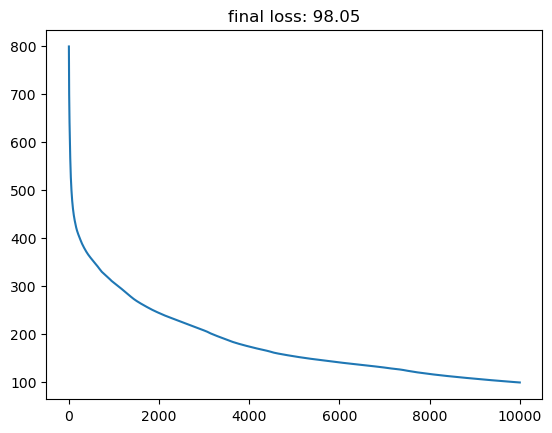

In [11]:
import matplotlib.pyplot as plt

plt.plot(losses)
plt.title(f"final loss: {losses[-1]:.2f}");

In [12]:
params

{'layer0': {'w': array([[ 5.12789772e-01, -8.40387657e-01, -5.30834812e-01,
           1.72170721e-01, -6.63458919e-01, -1.26675888e+00,
          -2.05596343e+00,  2.65868065e+00,  3.66947641e-01,
           4.29515029e-02, -2.66482686e-01,  4.66198529e-01,
           9.33804002e-02,  6.33521918e-01, -4.84134551e-01,
           7.26966898e-01,  1.16046809e-02, -4.91186951e-01,
          -4.96702100e-01, -6.09793826e-01],
         [ 1.30490503e+00, -7.10102234e-01,  1.12818455e+00,
          -1.75134760e-01,  7.36978767e-01, -8.15242963e-01,
           2.38822429e-01,  3.56386664e-01,  1.04991936e+00,
          -7.24679466e-02, -6.08728838e-01, -1.44163902e-01,
          -3.37022460e-01, -1.72261037e+00,  1.06613722e+00,
          -1.05768444e-01,  1.12372995e+00, -1.27518813e+00,
          -6.45150631e-01,  1.08723124e+00],
         [-8.49054234e-01, -2.82291800e-01,  3.53659797e-02,
          -2.04344763e+00, -5.28713250e-01, -4.34125043e-01,
          -1.54742995e-01,  9.13036595e-0

## Theory: reading the confusion matrix

The probability is turned into a class with a threshold: $\text{class} = 1$ if $\hat{y} \ge 0.5$ (this is what `np.round` does).
Rows are the actual classes, columns the predicted ones. With `normalize='true'` each row sums to 1, so the diagonal gives the fraction of each class classified correctly (recall).

### Visualize trained model performance

We can use a confusion matrix to see how "confused" a model was.
Read more on [Wikipedia](https://en.wikipedia.org/wiki/Confusion_matrix).

[[0.95918367 0.04081633]
 [0.06048387 0.93951613]]


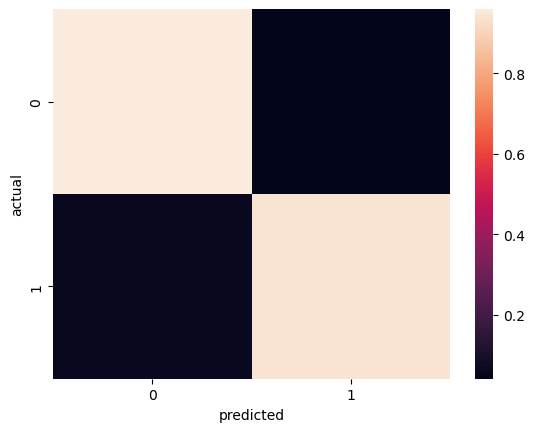

In [13]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

y_pred = kmodel(params, X_train.values)
print(M:=confusion_matrix(y_train, np.round(y_pred),normalize='true')) 

sns.heatmap(M)
plt.xlabel('predicted')
plt.ylabel('actual');

## Theory: train vs out-of-sample

The training loss only says how well the model fits data it has already seen. Performance on the held-out test set is the honest estimate of how it will behave on new molecules. A large gap between the two matrices signals **overfitting**.

### Visualize OOS model performance

We can use a confusion matrix to see how "confused" a model was.
Read more on [Wikipedia](https://en.wikipedia.org/wiki/Confusion_matrix).

[[0.75598086 0.24401914]
 [0.17592593 0.82407407]]


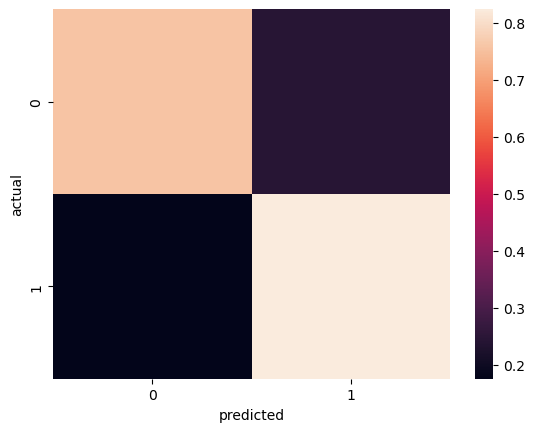

In [14]:
y_pred = kmodel(params, X_test.values)
print(M_oos:=confusion_matrix(y_test, np.round(y_pred),normalize='true')) 
sns.heatmap(M_oos)
plt.xlabel('predicted')
plt.ylabel('actual');